
Correlation results:
                       variable    n  pearson_r  spearman_r
0           Same month rainfall  238   0.113199    0.082236
1          Rainfall lag 1 month  237   0.323726    0.395433
2         Rainfall lag 2 months  236   0.390269    0.523430
3         Rainfall lag 3 months  235   0.432430    0.544769
4  3-month accumulated rainfall  236   0.329811    0.432080
5  6-month accumulated rainfall  233   0.475091    0.620978


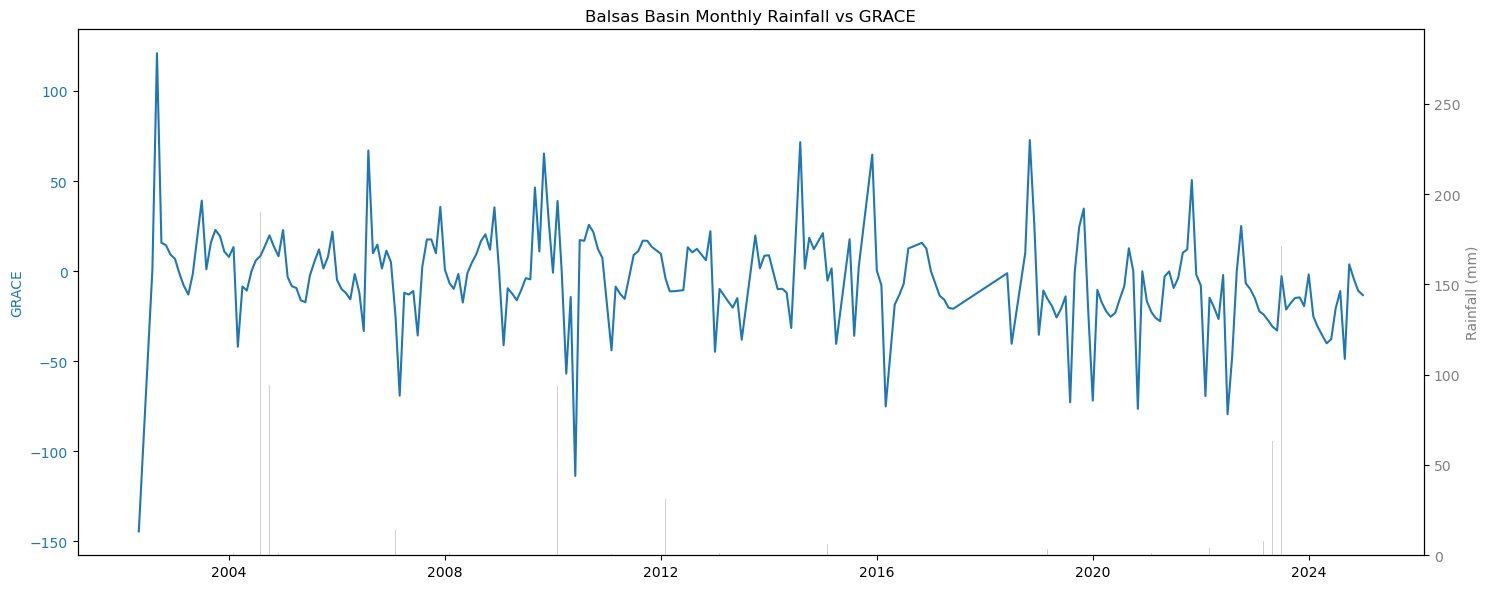

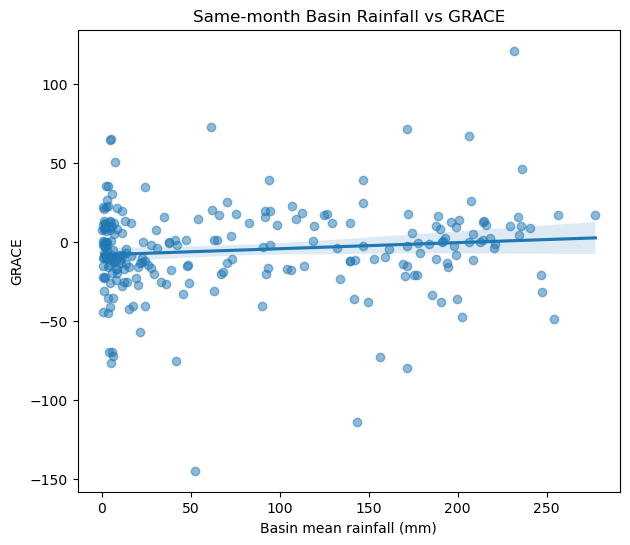

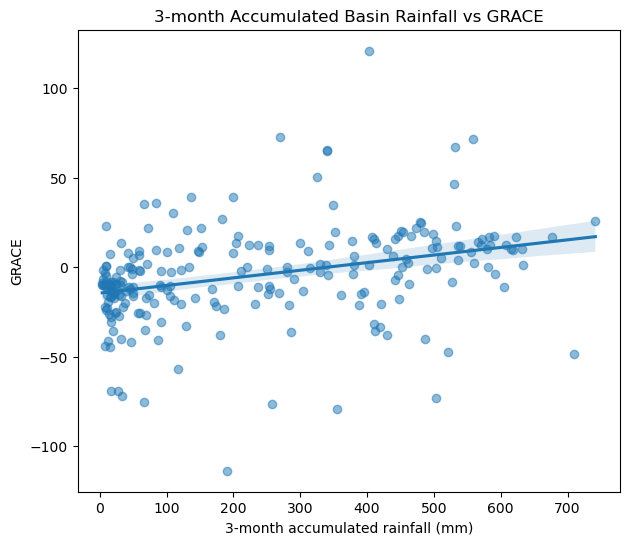


Saved files:
- balsas_rainfall_grace_merged.csv
- balsas_rainfall_grace_correlations.csv


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------
# 1. Load Excel file
# ---------------------------
file_path = "Depurado final data tesis.xlsx"   # change to your file name

grace = pd.read_excel(file_path, sheet_name="grace balsas")
rain = pd.read_excel(file_path, sheet_name="smn_lluvia_total_mensual")

# ---------------------------
# 2. Clean column names
# ---------------------------
grace.columns = grace.columns.str.strip()
rain.columns = rain.columns.str.strip()

# ---------------------------
# 3. Clean GRACE values
# ---------------------------
grace_col = "Water Equivalent Thickness – Land (GRACE, GRACE-FO JPL)"

def clean_grace_value(x):
    if pd.isna(x):
        return np.nan
    
    s = str(x).strip().replace(",", ".")
    
    try:
        val = float(s)
    except:
        return np.nan
    
    # fix malformed large values if decimal point was lost
    if abs(val) > 1000:
        val = val / 1_000_000
    
    return val

grace["GRACE_clean"] = grace[grace_col].apply(clean_grace_value)

# ---------------------------
# 4. Parse GRACE dates
# ---------------------------
grace["DateTime"] = pd.to_datetime(grace["DateTime"], errors="coerce")
grace["Date"] = grace["DateTime"].dt.to_period("M").dt.to_timestamp()

# Average if more than one GRACE observation per month
grace_monthly = (
    grace.groupby("Date", as_index=False)["GRACE_clean"]
    .mean()
    .sort_values("Date")
)

# ---------------------------
# 5. Clean rainfall data
# ---------------------------
rain["station_id"] = pd.to_numeric(rain["station_id"], errors="coerce")
rain["year"] = pd.to_numeric(rain["year"], errors="coerce")
rain["month"] = pd.to_numeric(rain["month"], errors="coerce")
rain["precip_mm"] = pd.to_numeric(rain["precip_mm"], errors="coerce")

rain["Date"] = pd.to_datetime(
    dict(year=rain["year"], month=rain["month"], day=1),
    errors="coerce"
)

# Keep only valid rows
rain_clean = rain.dropna(subset=["Date"]).copy()

# ---------------------------
# 6. Build basin monthly rainfall series
# ---------------------------
# Mean rainfall across all stations available each month
rain_basin = (
    rain_clean.groupby("Date", as_index=False)
    .agg(
        Rain_basin_mean=("precip_mm", "mean"),
        Rain_basin_median=("precip_mm", "median"),
        stations_reporting=("precip_mm", lambda x: x.notna().sum()),
        stations_total=("station_id", "nunique")
    )
    .sort_values("Date")
)

# Optional: fraction of stations reporting
rain_basin["reporting_fraction"] = (
    rain_basin["stations_reporting"] / rain_basin["stations_total"]
)

# ---------------------------
# 7. Merge rainfall and GRACE
# ---------------------------
df = pd.merge(rain_basin, grace_monthly, on="Date", how="inner")

# Keep months where both basin rainfall and GRACE exist
df = df.dropna(subset=["Rain_basin_mean", "GRACE_clean"]).copy()

# ---------------------------
# 8. Optional quality filter
# ---------------------------
# Keep only months where at least 50% of stations reported rainfall
df_filtered = df[df["reporting_fraction"] >= 0.5].copy()

# If this becomes too restrictive, use df instead of df_filtered
analysis_df = df_filtered.copy()

# ---------------------------
# 9. Create lagged and rolling rainfall variables
# ---------------------------
analysis_df = analysis_df.sort_values("Date").reset_index(drop=True)

analysis_df["Rain_lag1"] = analysis_df["Rain_basin_mean"].shift(1)
analysis_df["Rain_lag2"] = analysis_df["Rain_basin_mean"].shift(2)
analysis_df["Rain_lag3"] = analysis_df["Rain_basin_mean"].shift(3)

analysis_df["Rain_3mo"] = analysis_df["Rain_basin_mean"].rolling(3).sum()
analysis_df["Rain_6mo"] = analysis_df["Rain_basin_mean"].rolling(6).sum()

# ---------------------------
# 10. Correlation helper
# ---------------------------
def corr_report(data, x, y, name):
    sub = data[[x, y]].dropna()
    if len(sub) < 3:
        return {"variable": name, "n": len(sub), "pearson_r": np.nan, "spearman_r": np.nan}
    
    return {
        "variable": name,
        "n": len(sub),
        "pearson_r": sub[x].corr(sub[y], method="pearson"),
        "spearman_r": sub[x].corr(sub[y], method="spearman")
    }

results = [
    corr_report(analysis_df, "Rain_basin_mean", "GRACE_clean", "Same month rainfall"),
    corr_report(analysis_df, "Rain_lag1", "GRACE_clean", "Rainfall lag 1 month"),
    corr_report(analysis_df, "Rain_lag2", "GRACE_clean", "Rainfall lag 2 months"),
    corr_report(analysis_df, "Rain_lag3", "GRACE_clean", "Rainfall lag 3 months"),
    corr_report(analysis_df, "Rain_3mo", "GRACE_clean", "3-month accumulated rainfall"),
    corr_report(analysis_df, "Rain_6mo", "GRACE_clean", "6-month accumulated rainfall"),
]

results_df = pd.DataFrame(results)

print("\nCorrelation results:")
print(results_df)

# ---------------------------
# 11. Plot time series
# ---------------------------
fig, ax1 = plt.subplots(figsize=(15,6))

ax1.plot(analysis_df["Date"], analysis_df["GRACE_clean"], color="tab:blue", label="GRACE")
ax1.set_ylabel("GRACE", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.bar(
    analysis_df["Date"],
    analysis_df["Rain_basin_mean"],
    color="tab:gray",
    alpha=0.35,
    label="Basin mean rainfall"
)
ax2.set_ylabel("Rainfall (mm)", color="tab:gray")
ax2.tick_params(axis="y", labelcolor="tab:gray")

plt.title("Balsas Basin Monthly Rainfall vs GRACE")
fig.tight_layout()
plt.show()

# ---------------------------
# 12. Scatterplots
# ---------------------------
plt.figure(figsize=(7,6))
sns.regplot(data=analysis_df, x="Rain_basin_mean", y="GRACE_clean", scatter_kws={"alpha":0.5})
plt.title("Same-month Basin Rainfall vs GRACE")
plt.xlabel("Basin mean rainfall (mm)")
plt.ylabel("GRACE")
plt.show()

sub3 = analysis_df.dropna(subset=["Rain_3mo", "GRACE_clean"])
plt.figure(figsize=(7,6))
sns.regplot(data=sub3, x="Rain_3mo", y="GRACE_clean", scatter_kws={"alpha":0.5})
plt.title("3-month Accumulated Basin Rainfall vs GRACE")
plt.xlabel("3-month accumulated rainfall (mm)")
plt.ylabel("GRACE")
plt.show()

# ---------------------------
# 13. Save outputs
# ---------------------------
analysis_df.to_csv("balsas_rainfall_grace_merged.csv", index=False)
results_df.to_csv("balsas_rainfall_grace_correlations.csv", index=False)

print("\nSaved files:")
print("- balsas_rainfall_grace_merged.csv")
print("- balsas_rainfall_grace_correlations.csv")



Correlation summary:
                         comparison    n  pearson_r  spearman_r
0         Raw rainfall vs raw GRACE  238   0.113199    0.082236
1            Rain SMA6 vs raw GRACE  233   0.475091    0.620978
2           Rain SMA6 vs GRACE SMA6  233   0.111797    0.123158
3    6-mo rainfall sum vs raw GRACE  233   0.475091    0.620978
4                SRI-6 vs raw GRACE  233   0.475091    0.620978
5       SRI-6 vs standardized GRACE  233   0.475091    0.620978
6  SRI-6 vs standardized GRACE SMA6  233   0.111797    0.123158


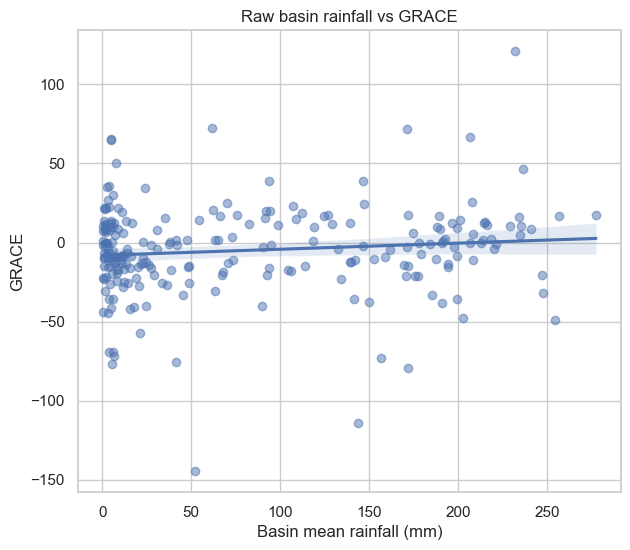

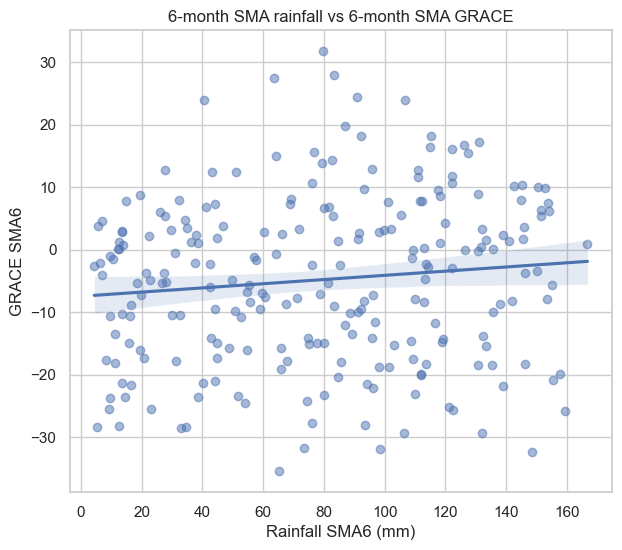

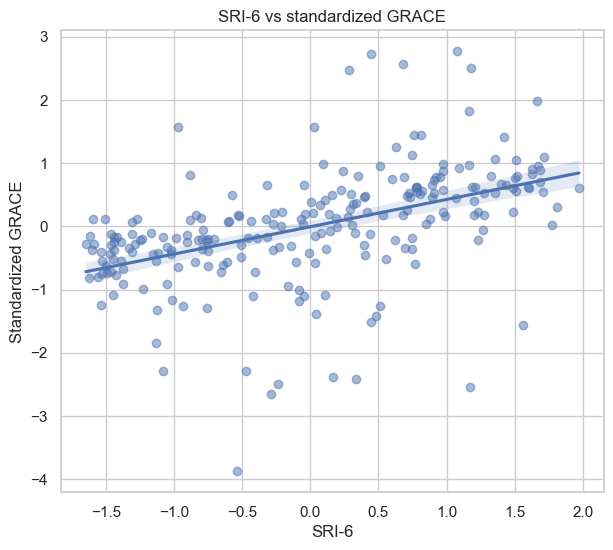


Cross-correlation (SRI-6 leading GRACE):
    lag_months  pearson_r    n
0            0   0.475091  233
1            1   0.389778  232
2            2   0.193143  231
3            3  -0.040608  230
4            4  -0.256177  229
5            5  -0.372764  228
6            6  -0.386852  227
7            7  -0.275461  226
8            8  -0.110092  225
9            9   0.077579  224
10          10   0.229753  223
11          11   0.308306  222
12          12   0.295276  221


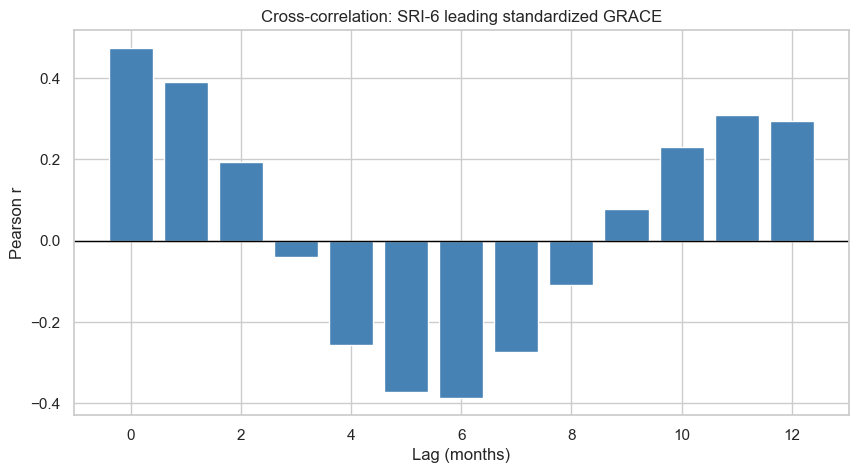

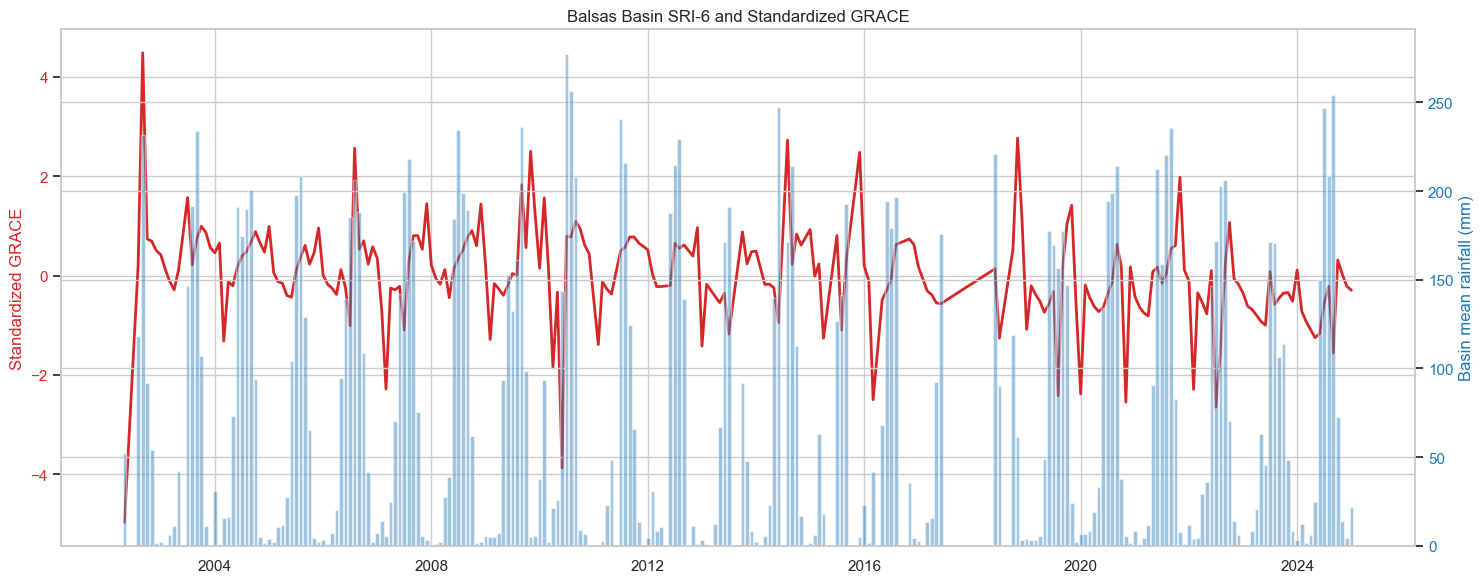


Saved:
- balsas_rain_grace_sma_sri.csv
- balsas_rain_grace_summary.csv
- balsas_sri6_grace_crosscorr.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------
# 1. Load file
# ---------------------------
file_path = "Depurado final data tesis.xlsx"

grace = pd.read_excel(file_path, sheet_name="grace balsas")
rain = pd.read_excel(file_path, sheet_name="smn_lluvia_total_mensual")

grace.columns = grace.columns.str.strip()
rain.columns = rain.columns.str.strip()

# ---------------------------
# 2. Clean GRACE values
# ---------------------------
grace_col = "Water Equivalent Thickness – Land (GRACE, GRACE-FO JPL)"

def clean_grace_value(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", ".")
    try:
        val = float(s)
    except:
        return np.nan
    
    # probable decimal-loss correction
    if abs(val) > 1000:
        val = val / 1_000_000
    return val

grace["GRACE_clean"] = grace[grace_col].apply(clean_grace_value)
grace["DateTime"] = pd.to_datetime(grace["DateTime"], errors="coerce")
grace["Date"] = grace["DateTime"].dt.to_period("M").dt.to_timestamp()

grace_monthly = (
    grace.groupby("Date", as_index=False)["GRACE_clean"]
    .mean()
    .sort_values("Date")
)

# ---------------------------
# 3. Clean rainfall
# ---------------------------
rain["station_id"] = pd.to_numeric(rain["station_id"], errors="coerce")
rain["year"] = pd.to_numeric(rain["year"], errors="coerce")
rain["month"] = pd.to_numeric(rain["month"], errors="coerce")
rain["precip_mm"] = pd.to_numeric(rain["precip_mm"], errors="coerce")

rain["Date"] = pd.to_datetime(
    dict(year=rain["year"], month=rain["month"], day=1),
    errors="coerce"
)

rain_clean = rain.dropna(subset=["Date"]).copy()

total_stations = rain_clean["station_id"].nunique()

# ---------------------------
# 4. Build basin rainfall series
# ---------------------------
rain_basin = (
    rain_clean.groupby("Date", as_index=False)
    .agg(
        Rain_basin_mean=("precip_mm", "mean"),
        Rain_basin_median=("precip_mm", "median"),
        stations_reporting=("precip_mm", lambda x: x.notna().sum())
    )
    .sort_values("Date")
)

rain_basin["stations_total"] = total_stations
rain_basin["reporting_fraction"] = rain_basin["stations_reporting"] / total_stations

# ---------------------------
# 5. Merge with GRACE
# ---------------------------
df = pd.merge(rain_basin, grace_monthly, on="Date", how="inner")
df = df.dropna(subset=["Rain_basin_mean", "GRACE_clean"]).copy()

# optional filter for data coverage
df = df[df["reporting_fraction"] >= 0.5].copy()

df = df.sort_values("Date").reset_index(drop=True)

# ---------------------------
# 6. Hydrologic smoothing / accumulation
# ---------------------------
# 6-month simple moving average
df["Rain_SMA6"] = df["Rain_basin_mean"].rolling(window=6, min_periods=6).mean()
df["GRACE_SMA6"] = df["GRACE_clean"].rolling(window=6, min_periods=6).mean()

# 6-month accumulated rainfall
df["Rain_6mo_sum"] = df["Rain_basin_mean"].rolling(window=6, min_periods=6).sum()

# standardized rainfall index based on 6-month accumulation
rain6_mean = df["Rain_6mo_sum"].mean(skipna=True)
rain6_std = df["Rain_6mo_sum"].std(skipna=True)

df["SRI_6"] = (df["Rain_6mo_sum"] - rain6_mean) / rain6_std

# Optional standardized GRACE too
grace_mean = df["GRACE_clean"].mean(skipna=True)
grace_std = df["GRACE_clean"].std(skipna=True)
df["GRACE_z"] = (df["GRACE_clean"] - grace_mean) / grace_std

grace_sma6_mean = df["GRACE_SMA6"].mean(skipna=True)
grace_sma6_std = df["GRACE_SMA6"].std(skipna=True)
df["GRACE_SMA6_z"] = (df["GRACE_SMA6"] - grace_sma6_mean) / grace_sma6_std

# ---------------------------
# 7. Correlation summary
# ---------------------------
def corr_pair(data, x, y, label):
    sub = data[[x, y]].dropna()
    if len(sub) < 3:
        return {"comparison": label, "n": len(sub), "pearson_r": np.nan, "spearman_r": np.nan}
    return {
        "comparison": label,
        "n": len(sub),
        "pearson_r": sub[x].corr(sub[y], method="pearson"),
        "spearman_r": sub[x].corr(sub[y], method="spearman")
    }

results = [
    corr_pair(df, "Rain_basin_mean", "GRACE_clean", "Raw rainfall vs raw GRACE"),
    corr_pair(df, "Rain_SMA6", "GRACE_clean", "Rain SMA6 vs raw GRACE"),
    corr_pair(df, "Rain_SMA6", "GRACE_SMA6", "Rain SMA6 vs GRACE SMA6"),
    corr_pair(df, "Rain_6mo_sum", "GRACE_clean", "6-mo rainfall sum vs raw GRACE"),
    corr_pair(df, "SRI_6", "GRACE_clean", "SRI-6 vs raw GRACE"),
    corr_pair(df, "SRI_6", "GRACE_z", "SRI-6 vs standardized GRACE"),
    corr_pair(df, "SRI_6", "GRACE_SMA6_z", "SRI-6 vs standardized GRACE SMA6"),
]

results_df = pd.DataFrame(results)
print("\nCorrelation summary:")
print(results_df)

# ---------------------------
# 8. Scatter / cross plots
# ---------------------------
sns.set(style="whitegrid")

# Raw rainfall vs GRACE
plt.figure(figsize=(7,6))
sns.regplot(data=df, x="Rain_basin_mean", y="GRACE_clean", scatter_kws={"alpha":0.5})
plt.title("Raw basin rainfall vs GRACE")
plt.xlabel("Basin mean rainfall (mm)")
plt.ylabel("GRACE")
plt.show()

# Rain SMA6 vs GRACE SMA6
sub_sma = df.dropna(subset=["Rain_SMA6", "GRACE_SMA6"])
plt.figure(figsize=(7,6))
sns.regplot(data=sub_sma, x="Rain_SMA6", y="GRACE_SMA6", scatter_kws={"alpha":0.5})
plt.title("6-month SMA rainfall vs 6-month SMA GRACE")
plt.xlabel("Rainfall SMA6 (mm)")
plt.ylabel("GRACE SMA6")
plt.show()

# SRI-6 vs standardized GRACE
sub_sri = df.dropna(subset=["SRI_6", "GRACE_z"])
plt.figure(figsize=(7,6))
sns.regplot(data=sub_sri, x="SRI_6", y="GRACE_z", scatter_kws={"alpha":0.5})
plt.title("SRI-6 vs standardized GRACE")
plt.xlabel("SRI-6")
plt.ylabel("Standardized GRACE")
plt.show()

# ---------------------------
# 9. Cross-correlation across lags
# ---------------------------
# Positive lag here means rainfall leads GRACE by that many months
max_lag = 12
lag_results = []

for lag in range(0, max_lag + 1):
    temp = df[["SRI_6", "GRACE_z"]].copy()
    temp["SRI_6_lagged"] = temp["SRI_6"].shift(lag)
    sub = temp[["SRI_6_lagged", "GRACE_z"]].dropna()
    
    if len(sub) >= 3:
        r = sub["SRI_6_lagged"].corr(sub["GRACE_z"], method="pearson")
    else:
        r = np.nan
    
    lag_results.append({"lag_months": lag, "pearson_r": r, "n": len(sub)})

lag_df = pd.DataFrame(lag_results)
print("\nCross-correlation (SRI-6 leading GRACE):")
print(lag_df)

plt.figure(figsize=(10,5))
plt.axhline(0, color="black", linewidth=1)
plt.bar(lag_df["lag_months"], lag_df["pearson_r"], color="steelblue")
plt.title("Cross-correlation: SRI-6 leading standardized GRACE")
plt.xlabel("Lag (months)")
plt.ylabel("Pearson r")
plt.show()

# ---------------------------
# 10. Time series plot
# ---------------------------
fig, ax1 = plt.subplots(figsize=(15,6))

# GRACE as line
ax1.plot(df["Date"], df["GRACE_z"], color="tab:red", linewidth=2, label="Standardized GRACE")
ax1.set_ylabel("Standardized GRACE", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")

# Rainfall as bars
ax2 = ax1.twinx()
ax2.bar(df["Date"], df["Rain_basin_mean"], width=25, color="tab:blue", alpha=0.45, label="Basin rainfall")
ax2.set_ylabel("Basin mean rainfall (mm)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")

plt.title("Balsas Basin SRI-6 and Standardized GRACE")
fig.tight_layout()
plt.show()

# ---------------------------
# 11. Save outputs
# ---------------------------
df.to_csv("balsas_rain_grace_sma_sri.csv", index=False)
results_df.to_csv("balsas_rain_grace_summary.csv", index=False)
lag_df.to_csv("balsas_sri6_grace_crosscorr.csv", index=False)

print("\nSaved:")
print("- balsas_rain_grace_sma_sri.csv")
print("- balsas_rain_grace_summary.csv")
print("- balsas_sri6_grace_crosscorr.csv")


Unique state_folder values: ['gro', 'jal', 'mex', 'mich', 'mor', 'oax', 'pue', 'tlax']
Number of Puebla rows: 37284
Number of Puebla stations: 59

Correlation summary:
                                comparison    n  pearson_r  spearman_r
0         Raw Puebla rainfall vs raw GRACE  185   0.051786    0.033149
1            Puebla Rain SMA6 vs raw GRACE  180   0.482566    0.607543
2           Puebla Rain SMA6 vs GRACE SMA6  180   0.100155    0.096505
3    Puebla 6-mo rainfall sum vs raw GRACE  180   0.482566    0.607543
4                Puebla SRI-6 vs raw GRACE  180   0.482566    0.607543
5       Puebla SRI-6 vs standardized GRACE  180   0.482566    0.607543
6  Puebla SRI-6 vs standardized GRACE SMA6  180   0.100155    0.096505

Cross-correlation (Puebla SRI-6 leading GRACE):
    lag_months  pearson_r    n
0            0   0.482566  180
1            1   0.428011  179
2            2   0.235437  178
3            3   0.017172  177
4            4  -0.184228  176
5            5  -0.299431  17

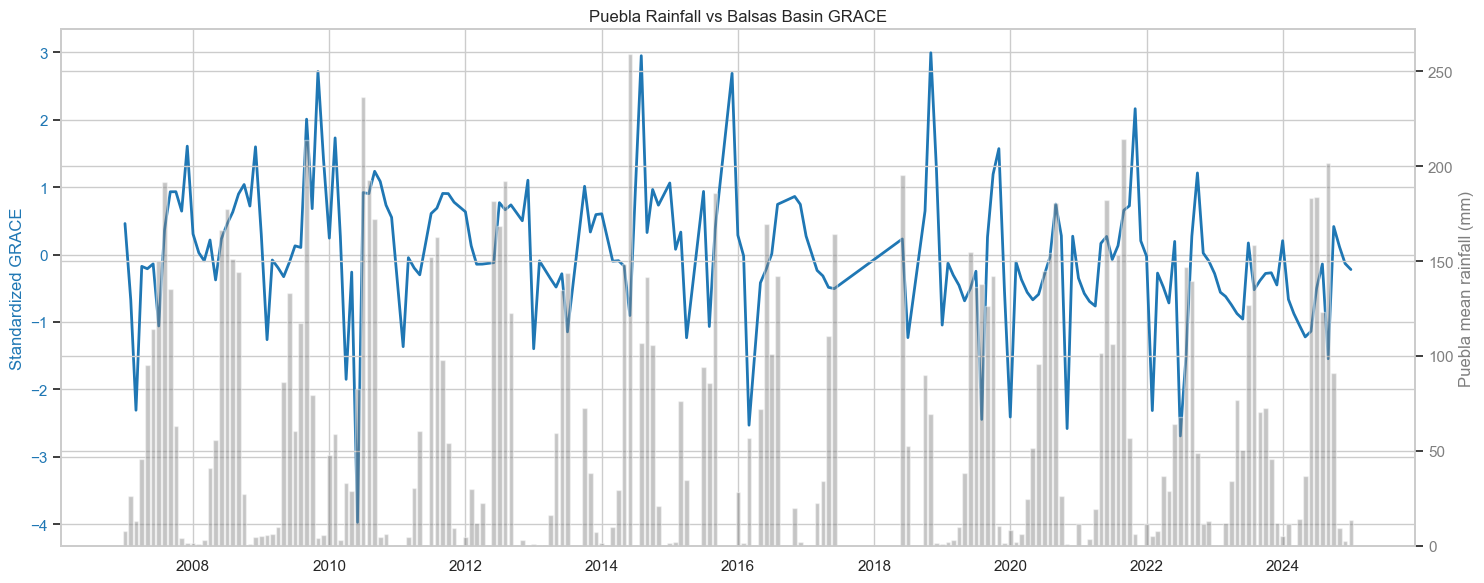

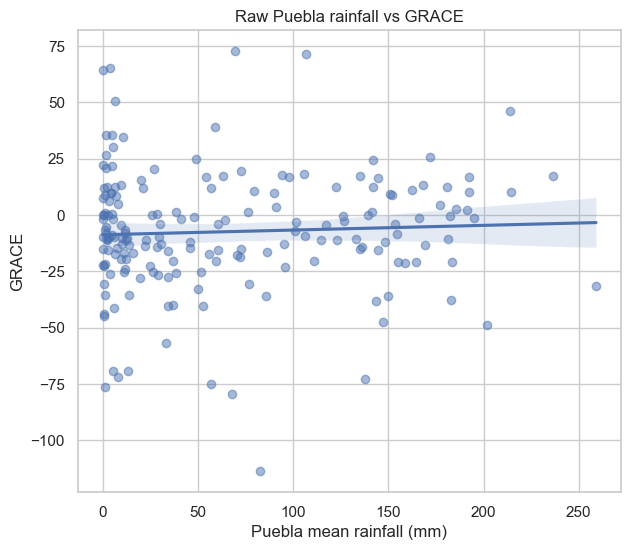

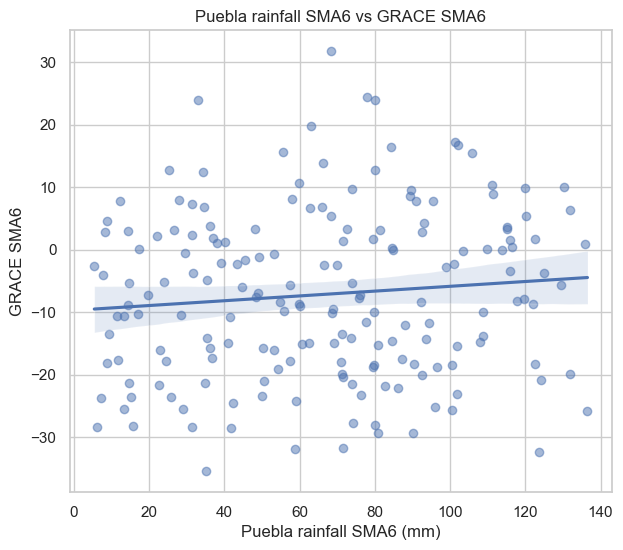

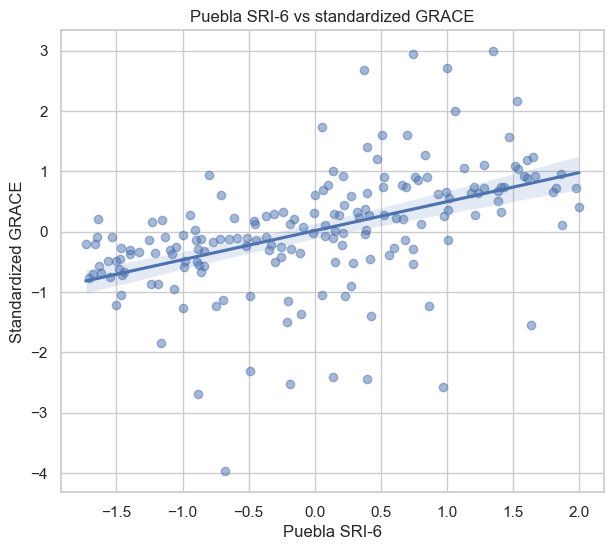

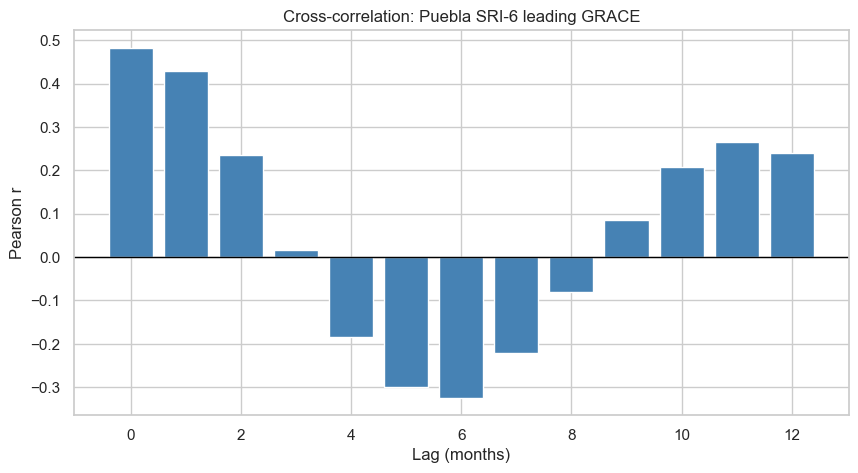


Saved:
- puebla_rain_grace_sma_sri.csv
- puebla_rain_grace_summary.csv
- puebla_sri6_grace_crosscorr.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------
# 1. Load file
# ---------------------------
file_path = "Depurado final data tesis.xlsx"

grace = pd.read_excel(file_path, sheet_name="grace balsas")
rain = pd.read_excel(file_path, sheet_name="smn_lluvia_total_mensual")

grace.columns = grace.columns.str.strip()
rain.columns = rain.columns.str.strip()

# ---------------------------
# 2. Clean GRACE values
# ---------------------------
grace_col = "Water Equivalent Thickness – Land (GRACE, GRACE-FO JPL)"

def clean_grace_value(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", ".")
    try:
        val = float(s)
    except:
        return np.nan
    
    if abs(val) > 1000:
        val = val / 1_000_000
    
    return val

grace["GRACE_clean"] = grace[grace_col].apply(clean_grace_value)
grace["DateTime"] = pd.to_datetime(grace["DateTime"], errors="coerce")
grace["Date"] = grace["DateTime"].dt.to_period("M").dt.to_timestamp()

grace_monthly = (
    grace.groupby("Date", as_index=False)["GRACE_clean"]
    .mean()
    .sort_values("Date")
)

# ---------------------------
# 3. Clean rainfall data
# ---------------------------
rain.columns = rain.columns.str.strip()
rain["state_folder"] = rain["state_folder"].astype(str).str.strip().str.lower()

rain["station_id"] = pd.to_numeric(rain["station_id"], errors="coerce")
rain["year"] = pd.to_numeric(rain["year"], errors="coerce")
rain["month"] = pd.to_numeric(rain["month"], errors="coerce")
rain["precip_mm"] = pd.to_numeric(rain["precip_mm"], errors="coerce")

rain["Date"] = pd.to_datetime(
    dict(year=rain["year"], month=rain["month"], day=1),
    errors="coerce"
)

# ---------------------------
# 4. Filter Puebla stations only
# ---------------------------
rain_puebla = rain[rain["state_folder"] == "pue"].copy()

print("Unique state_folder values:", sorted(rain["state_folder"].dropna().unique()))
print("Number of Puebla rows:", len(rain_puebla))
print("Number of Puebla stations:", rain_puebla["station_id"].nunique())

# ---------------------------
# 5. Build Puebla monthly rainfall series
# ---------------------------
total_puebla_stations = rain_puebla["station_id"].nunique()

rain_puebla_monthly = (
    rain_puebla.groupby("Date", as_index=False)
    .agg(
        Rain_puebla_mean=("precip_mm", "mean"),
        Rain_puebla_median=("precip_mm", "median"),
        stations_reporting=("precip_mm", lambda x: x.notna().sum())
    )
    .sort_values("Date")
)

rain_puebla_monthly["stations_total"] = total_puebla_stations
rain_puebla_monthly["reporting_fraction"] = (
    rain_puebla_monthly["stations_reporting"] / total_puebla_stations
)

# ---------------------------
# 6. Merge with basin GRACE
# ---------------------------
df = pd.merge(rain_puebla_monthly, grace_monthly, on="Date", how="inner")
df = df.dropna(subset=["Rain_puebla_mean", "GRACE_clean"]).copy()

# Optional quality filter
df = df[df["reporting_fraction"] >= 0.5].copy()

df = df.sort_values("Date").reset_index(drop=True)

# ---------------------------
# 7. Hydrologic variables
# ---------------------------
df["Rain_SMA6"] = df["Rain_puebla_mean"].rolling(window=6, min_periods=6).mean()
df["GRACE_SMA6"] = df["GRACE_clean"].rolling(window=6, min_periods=6).mean()

df["Rain_6mo_sum"] = df["Rain_puebla_mean"].rolling(window=6, min_periods=6).sum()

rain6_mean = df["Rain_6mo_sum"].mean(skipna=True)
rain6_std = df["Rain_6mo_sum"].std(skipna=True)
df["SRI_6"] = (df["Rain_6mo_sum"] - rain6_mean) / rain6_std

grace_mean = df["GRACE_clean"].mean(skipna=True)
grace_std = df["GRACE_clean"].std(skipna=True)
df["GRACE_z"] = (df["GRACE_clean"] - grace_mean) / grace_std

grace_sma6_mean = df["GRACE_SMA6"].mean(skipna=True)
grace_sma6_std = df["GRACE_SMA6"].std(skipna=True)
df["GRACE_SMA6_z"] = (df["GRACE_SMA6"] - grace_sma6_mean) / grace_sma6_std

# ---------------------------
# 8. Correlation summary
# ---------------------------
def corr_pair(data, x, y, label):
    sub = data[[x, y]].dropna()
    if len(sub) < 3:
        return {"comparison": label, "n": len(sub), "pearson_r": np.nan, "spearman_r": np.nan}
    return {
        "comparison": label,
        "n": len(sub),
        "pearson_r": sub[x].corr(sub[y], method="pearson"),
        "spearman_r": sub[x].corr(sub[y], method="spearman")
    }

results = [
    corr_pair(df, "Rain_puebla_mean", "GRACE_clean", "Raw Puebla rainfall vs raw GRACE"),
    corr_pair(df, "Rain_SMA6", "GRACE_clean", "Puebla Rain SMA6 vs raw GRACE"),
    corr_pair(df, "Rain_SMA6", "GRACE_SMA6", "Puebla Rain SMA6 vs GRACE SMA6"),
    corr_pair(df, "Rain_6mo_sum", "GRACE_clean", "Puebla 6-mo rainfall sum vs raw GRACE"),
    corr_pair(df, "SRI_6", "GRACE_clean", "Puebla SRI-6 vs raw GRACE"),
    corr_pair(df, "SRI_6", "GRACE_z", "Puebla SRI-6 vs standardized GRACE"),
    corr_pair(df, "SRI_6", "GRACE_SMA6_z", "Puebla SRI-6 vs standardized GRACE SMA6"),
]

results_df = pd.DataFrame(results)
print("\nCorrelation summary:")
print(results_df)

# ---------------------------
# 9. Cross-correlation
# ---------------------------
max_lag = 12
lag_results = []

for lag in range(0, max_lag + 1):
    temp = df[["SRI_6", "GRACE_z"]].copy()
    temp["SRI_6_lagged"] = temp["SRI_6"].shift(lag)
    sub = temp[["SRI_6_lagged", "GRACE_z"]].dropna()
    
    if len(sub) >= 3:
        r = sub["SRI_6_lagged"].corr(sub["GRACE_z"], method="pearson")
    else:
        r = np.nan
    
    lag_results.append({"lag_months": lag, "pearson_r": r, "n": len(sub)})

lag_df = pd.DataFrame(lag_results)
print("\nCross-correlation (Puebla SRI-6 leading GRACE):")
print(lag_df)

# ---------------------------
# 10. Time series plot
# ---------------------------
fig, ax1 = plt.subplots(figsize=(15,6))

ax1.plot(df["Date"], df["GRACE_z"], color="tab:blue", linewidth=2, label="Standardized GRACE")
ax1.set_ylabel("Standardized GRACE", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.bar(df["Date"], df["Rain_puebla_mean"], width=25, color="tab:gray", alpha=0.45, label="Puebla rainfall")
ax2.set_ylabel("Puebla mean rainfall (mm)", color="tab:gray")
ax2.tick_params(axis="y", labelcolor="tab:gray")

plt.title("Puebla Rainfall vs Balsas Basin GRACE")
fig.tight_layout()
plt.show()

# ---------------------------
# 11. Scatterplots
# ---------------------------
plt.figure(figsize=(7,6))
sns.regplot(data=df, x="Rain_puebla_mean", y="GRACE_clean", scatter_kws={"alpha":0.5})
plt.title("Raw Puebla rainfall vs GRACE")
plt.xlabel("Puebla mean rainfall (mm)")
plt.ylabel("GRACE")
plt.show()

sub_sma = df.dropna(subset=["Rain_SMA6", "GRACE_SMA6"])
plt.figure(figsize=(7,6))
sns.regplot(data=sub_sma, x="Rain_SMA6", y="GRACE_SMA6", scatter_kws={"alpha":0.5})
plt.title("Puebla rainfall SMA6 vs GRACE SMA6")
plt.xlabel("Puebla rainfall SMA6 (mm)")
plt.ylabel("GRACE SMA6")
plt.show()

sub_sri = df.dropna(subset=["SRI_6", "GRACE_z"])
plt.figure(figsize=(7,6))
sns.regplot(data=sub_sri, x="SRI_6", y="GRACE_z", scatter_kws={"alpha":0.5})
plt.title("Puebla SRI-6 vs standardized GRACE")
plt.xlabel("Puebla SRI-6")
plt.ylabel("Standardized GRACE")
plt.show()

# ---------------------------
# 12. Cross-correlation bar plot
# ---------------------------
plt.figure(figsize=(10,5))
plt.axhline(0, color="black", linewidth=1)
plt.bar(lag_df["lag_months"], lag_df["pearson_r"], color="steelblue")
plt.title("Cross-correlation: Puebla SRI-6 leading GRACE")
plt.xlabel("Lag (months)")
plt.ylabel("Pearson r")
plt.show()

# ---------------------------
# 13. Save outputs
# ---------------------------
df.to_csv("puebla_rain_grace_sma_sri.csv", index=False)
results_df.to_csv("puebla_rain_grace_summary.csv", index=False)
lag_df.to_csv("puebla_sri6_grace_crosscorr.csv", index=False)

print("\nSaved:")
print("- puebla_rain_grace_sma_sri.csv")
print("- puebla_rain_grace_summary.csv")
print("- puebla_sri6_grace_crosscorr.csv")

In [6]:
import pandas as pd
import numpy as np
from pathlib import Path

# =========================================================
# CONFIG
# =========================================================
file_path = "Depurado final data tesis.xlsx"   # <- change if needed
output_dir = Path("outputs_availability_analysis")
output_dir.mkdir(exist_ok=True)

# =========================================================
# HELPERS
# =========================================================
def clean_num(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", ".")
    try:
        return float(s)
    except:
        return np.nan

def clean_grace_value(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", ".")
    try:
        val = float(s)
    except:
        return np.nan
    if abs(val) > 1000:
        val = val / 1_000_000
    return val

def annual_rain_summary(df, rain_col="precip_mm", station_col="station_id"):
    temp = df.copy()

    station_year = (
        temp.groupby(["year", station_col], as_index=False)
        .agg(
            annual_total_station=(rain_col, "sum"),
            months_reporting=(rain_col, lambda x: x.notna().sum())
        )
    )

    annual = (
        temp.groupby("year", as_index=False)
        .agg(
            annual_mean_monthly_rain=(rain_col, "mean"),
            annual_median_monthly_rain=(rain_col, "median"),
            station_month_obs=(rain_col, lambda x: x.notna().sum()),
            stations_present=(station_col, "nunique")
        )
    )

    annual_station_total = (
        station_year.groupby("year", as_index=False)
        .agg(
            annual_mean_station_total=("annual_total_station", "mean"),
            annual_median_station_total=("annual_total_station", "median"),
            annual_min_station_total=("annual_total_station", "min"),
            annual_max_station_total=("annual_total_station", "max"),
            stations_with_any_data=("annual_total_station", "count")
        )
    )

    return annual.merge(annual_station_total, on="year", how="left")

def find_header_row(df_raw):
    for i in range(len(df_raw)):
        row_vals = [str(v).strip().lower() for v in df_raw.iloc[i].tolist()]
        if ("año" in row_vals or "ano" in row_vals) and "clave" in row_vals:
            return i
    return None

# =========================================================
# LOAD SHEETS
# =========================================================
sheet1 = pd.read_excel(file_path, sheet_name="disponibilidad media dof")
sheet2 = pd.read_excel(file_path, sheet_name="estadistica conagua dof publica")
sheet3_raw = pd.read_excel(file_path, sheet_name="disponibilidad por acuifero2023", header=None)
grace = pd.read_excel(file_path, sheet_name="grace balsas")
rain = pd.read_excel(file_path, sheet_name="smn_lluvia_total_mensual")

sheet1.columns = [str(c).strip() for c in sheet1.columns]
sheet2.columns = [str(c).strip() for c in sheet2.columns]
grace.columns = [str(c).strip() for c in grace.columns]
rain.columns = [str(c).strip() for c in rain.columns]

# =========================================================
# 1) VERIFY OVERLAP IN FIRST 3 SHEETS
# =========================================================

# ---- SHEET 1 YEARS: explicit Año column
sheet1_year_col = "Año"
if sheet1_year_col not in sheet1.columns:
    raise ValueError(f"Expected year column '{sheet1_year_col}' not found in sheet1. Columns: {list(sheet1.columns)}")

sheet1_years = (
    pd.to_numeric(sheet1[sheet1_year_col], errors="coerce")
    .dropna()
    .astype(int)
)
sheet1_years = sorted([y for y in sheet1_years.tolist() if 1900 <= y <= 2100])

# ---- SHEET 2 YEARS
sheet2["Año"] = pd.to_numeric(sheet2["Año"], errors="coerce")
sheet2_years = sorted(sheet2["Año"].dropna().astype(int).unique().tolist())

# ---- SHEET 3 YEARS
header_row = find_header_row(sheet3_raw)
if header_row is None:
    raise ValueError("Could not find embedded header row in 'disponibilidad por acuifero2023'.")

sheet3 = sheet3_raw.iloc[header_row:].copy()
sheet3.columns = sheet3.iloc[0]
sheet3 = sheet3.iloc[1:].copy()
sheet3.columns = [str(c).strip() for c in sheet3.columns]

if "año" not in sheet3.columns:
    raise ValueError(f"No 'año' column found in cleaned sheet3. Columns: {list(sheet3.columns)}")

sheet3["año"] = pd.to_numeric(sheet3["año"], errors="coerce")
sheet3_years = sorted(sheet3["año"].dropna().astype(int).unique().tolist())

overlap_12 = sorted(set(sheet1_years).intersection(sheet2_years))
overlap_23 = sorted(set(sheet2_years).intersection(sheet3_years))
overlap_123 = sorted(set(sheet1_years).intersection(sheet2_years).intersection(sheet3_years))

overlap_text = []
overlap_text.append(f"Years in 'disponibilidad media dof': {sheet1_years}")
overlap_text.append(f"Years in 'estadistica conagua dof publica': {sheet2_years}")
overlap_text.append(f"Years in 'disponibilidad por acuifero2023': {sheet3_years}")
overlap_text.append("")
overlap_text.append(f"Overlap sheet1 & sheet2: {overlap_12}")
overlap_text.append(f"Overlap sheet2 & sheet3: {overlap_23}")
overlap_text.append(f"Overlap all three: {overlap_123}")

(output_dir / "overlap_summary.txt").write_text("\n".join(overlap_text), encoding="utf-8")
print("\n".join(overlap_text))

# =========================================================
# 2) CLEAN MASTER AVAILABILITY SHEET
# =========================================================
availability = sheet2.copy()

num_cols_avail = [
    "Clave Acuífero",
    "Recarga Total Media Anual",
    "Descarga Natural Comprometida",
    "Volumen concesionado/asignadode aguas Subterráneas",
    "Volumen de agua correspondiente a reservas, reglamentos y programación hídrica",
    "Volumen de extracción de aguas subterráneas",
    "Disponibilidad",
    "Año",
    "Año_archivo"
]

for col in num_cols_avail:
    if col in availability.columns:
        availability[col] = availability[col].apply(clean_num)

for col in ["Acuífero", "Región Hidrológico-Administrativa", "Situación", "Condición"]:
    if col in availability.columns:
        availability[col] = availability[col].astype(str).str.strip()

for col in ["Fecha de Corte", "Fecha de Publicación"]:
    if col in availability.columns:
        availability[col] = pd.to_datetime(availability[col], errors="coerce")

availability.to_csv(output_dir / "availability_master_clean.csv", index=False, encoding="utf-8-sig")

# =========================================================
# 3) BUILD ANNUAL GRACE
# =========================================================
grace_col = "Water Equivalent Thickness – Land (GRACE, GRACE-FO JPL)"
grace["GRACE_clean"] = grace[grace_col].apply(clean_grace_value)
grace["DateTime"] = pd.to_datetime(grace["DateTime"], errors="coerce")
grace["year"] = grace["DateTime"].dt.year
grace["month"] = grace["DateTime"].dt.month
grace["Date"] = grace["DateTime"].dt.to_period("M").dt.to_timestamp()

grace_monthly = (
    grace.groupby(["year", "month", "Date"], as_index=False)
    .agg(GRACE_monthly_mean=("GRACE_clean", "mean"))
    .sort_values("Date")
)

grace_annual = (
    grace_monthly.groupby("year", as_index=False)
    .agg(
        grace_annual_mean=("GRACE_monthly_mean", "mean"),
        grace_annual_median=("GRACE_monthly_mean", "median"),
        grace_annual_min=("GRACE_monthly_mean", "min"),
        grace_annual_max=("GRACE_monthly_mean", "max"),
        grace_months_available=("GRACE_monthly_mean", lambda x: x.notna().sum())
    )
)

grace_annual.to_csv(output_dir / "grace_annual_summary.csv", index=False, encoding="utf-8-sig")

# =========================================================
# 4) CLEAN RAINFALL
# =========================================================
rain["station_id"] = pd.to_numeric(rain["station_id"], errors="coerce")
rain["year"] = pd.to_numeric(rain["year"], errors="coerce")
rain["month"] = pd.to_numeric(rain["month"], errors="coerce")
rain["precip_mm"] = pd.to_numeric(rain["precip_mm"], errors="coerce")
rain["state_folder"] = rain["state_folder"].astype(str).str.strip().str.lower()

rain["Date"] = pd.to_datetime(
    dict(year=rain["year"], month=rain["month"], day=1),
    errors="coerce"
)

rain_clean = rain.dropna(subset=["Date", "year", "month"]).copy()

# =========================================================
# 5) ANNUAL RAINFALL WHOLE DATASET
# =========================================================
rain_whole_annual = annual_rain_summary(rain_clean, "precip_mm", "station_id")
rain_whole_annual = rain_whole_annual.rename(columns={
    "annual_mean_monthly_rain": "rain_whole_annual_mean_monthly",
    "annual_median_monthly_rain": "rain_whole_annual_median_monthly",
    "annual_mean_station_total": "rain_whole_annual_mean_station_total",
    "annual_median_station_total": "rain_whole_annual_median_station_total",
    "annual_min_station_total": "rain_whole_annual_min_station_total",
    "annual_max_station_total": "rain_whole_annual_max_station_total",
    "stations_present": "rain_whole_stations_present",
    "stations_with_any_data": "rain_whole_stations_with_any_data",
    "station_month_obs": "rain_whole_station_month_obs"
})
rain_whole_annual.to_csv(output_dir / "rain_annual_whole.csv", index=False, encoding="utf-8-sig")

# =========================================================
# 6) ANNUAL RAINFALL PUEBLA ONLY
# =========================================================
state_codes = sorted(rain_clean["state_folder"].dropna().unique().tolist())
print("\nAvailable state_folder codes:", state_codes[:50])

puebla_codes = {"pue", "puebla"}
rain_puebla = rain_clean[rain_clean["state_folder"].isin(puebla_codes)].copy()

if rain_puebla.empty:
    print("\nWARNING: No Puebla rows found with codes {'pue', 'puebla'}.")
    rain_puebla_annual = pd.DataFrame(columns=["year"])
else:
    rain_puebla_annual = annual_rain_summary(rain_puebla, "precip_mm", "station_id")
    rain_puebla_annual = rain_puebla_annual.rename(columns={
        "annual_mean_monthly_rain": "rain_puebla_annual_mean_monthly",
        "annual_median_monthly_rain": "rain_puebla_annual_median_monthly",
        "annual_mean_station_total": "rain_puebla_annual_mean_station_total",
        "annual_median_station_total": "rain_puebla_annual_median_station_total",
        "annual_min_station_total": "rain_puebla_annual_min_station_total",
        "annual_max_station_total": "rain_puebla_annual_max_station_total",
        "stations_present": "rain_puebla_stations_present",
        "stations_with_any_data": "rain_puebla_stations_with_any_data",
        "station_month_obs": "rain_puebla_station_month_obs"
    })

rain_puebla_annual.to_csv(output_dir / "rain_annual_puebla.csv", index=False, encoding="utf-8-sig")

# =========================================================
# 7) MERGE EVERYTHING
# =========================================================
merged = availability.copy()

merged = merged.merge(grace_annual, left_on="Año", right_on="year", how="left").drop(columns=["year"], errors="ignore")
merged = merged.merge(rain_whole_annual, left_on="Año", right_on="year", how="left").drop(columns=["year"], errors="ignore")
merged = merged.merge(rain_puebla_annual, left_on="Año", right_on="year", how="left").drop(columns=["year"], errors="ignore")

merged = merged.sort_values(["Año", "Clave Acuífero"]).reset_index(drop=True)

merged.to_csv(output_dir / "availability_hydroclimate_merged.csv", index=False, encoding="utf-8-sig")

analysis_ready = merged[merged["grace_annual_mean"].notna()].copy()
analysis_ready.to_csv(output_dir / "availability_hydroclimate_analysis_ready.csv", index=False, encoding="utf-8-sig")

print("\nSaved outputs to:", output_dir.resolve())
print("\nMerged preview:")
print(merged.head(10))

Years in 'disponibilidad media dof': [2013, 2015, 2018, 2020]
Years in 'estadistica conagua dof publica': [2003, 2009, 2011, 2013, 2015, 2018, 2020, 2023]
Years in 'disponibilidad por acuifero2023': [2023]

Overlap sheet1 & sheet2: [2013, 2015, 2018, 2020]
Overlap sheet2 & sheet3: [2023]
Overlap all three: []

Available state_folder codes: ['gro', 'jal', 'mex', 'mich', 'mor', 'oax', 'pue', 'tlax']

Saved outputs to: C:\Users\omari\Documents\12 semestre\tesis\nuevo analsiis\outputs_availability_analysis

Merged preview:
   N.P.  Clave Acuífero                     Acuífero Clave RHA  \
0   127          2101.0        Valle de Tecamachalco        IV   
1   128          2102.0              Libres-Oriental        IV   
2   129          2103.0  Atlixco-Izúcar de Matamoros        IV   
3   130          2104.0              Valle de Puebla        IV   
4   170          2101.0        Valle de Tecamachalco        IV   
5   171          2102.0              Libres-Oriental        IV   
6   172      

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# =========================================================
# CONFIG
# =========================================================
input_file = "outputs_availability_analysis/availability_hydroclimate_merged.csv"
output_dir = Path("graficos finales")
output_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="talk")

# =========================================================
# LOAD
# =========================================================
df = pd.read_csv(input_file)

# numeric cleanup just in case
num_cols = [
    "Año", "Clave Acuífero", "Disponibilidad",
    "grace_annual_mean", "grace_annual_median", "grace_annual_min", "grace_annual_max", "grace_months_available",
    "rain_whole_annual_mean_monthly", "rain_whole_annual_median_monthly",
    "rain_whole_annual_mean_station_total", "rain_whole_annual_median_station_total",
    "rain_whole_annual_min_station_total", "rain_whole_annual_max_station_total",
    "rain_whole_stations_present", "rain_whole_stations_with_any_data", "rain_whole_station_month_obs",
    "rain_puebla_annual_mean_monthly", "rain_puebla_annual_median_monthly",
    "rain_puebla_annual_mean_station_total", "rain_puebla_annual_median_station_total",
    "rain_puebla_annual_min_station_total", "rain_puebla_annual_max_station_total",
    "rain_puebla_stations_present", "rain_puebla_stations_with_any_data", "rain_puebla_station_month_obs"
]

for col in num_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# deduplicated annual frames for climate-only plots
grace_year = (
    df[["Año", "grace_annual_mean", "grace_annual_median", "grace_annual_min", "grace_annual_max", "grace_months_available"]]
    .drop_duplicates()
    .sort_values("Año")
)

rain_year = (
    df[[
        "Año",
        "rain_whole_annual_mean_station_total",
        "rain_whole_stations_with_any_data",
        "rain_puebla_annual_mean_station_total",
        "rain_puebla_stations_with_any_data"
    ]]
    .drop_duplicates()
    .sort_values("Año")
)

# =========================================================
# A) DATA COVERAGE: availability years by aquifer
# =========================================================
cov_av = df[["Año", "Acuífero", "Disponibilidad"]].dropna().copy()
cov_av["present"] = 1

plt.figure(figsize=(10, 5))
sns.scatterplot(data=cov_av, x="Año", y="Acuífero", size="present", legend=False, s=200)
plt.title("A) Cobertura temporal de disponibilidad por acuífero")
plt.xlabel("Año")
plt.ylabel("Acuífero")
plt.tight_layout()
plt.savefig(output_dir / "A_cobertura_disponibilidad_por_acuifero.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# B) DATA COVERAGE: GRACE months available by year
# =========================================================
plt.figure(figsize=(10, 5))
plt.bar(grace_year["Año"], grace_year["grace_months_available"], color="steelblue")
plt.title("B) Meses GRACE disponibles por año")
plt.xlabel("Año")
plt.ylabel("Número de meses")
plt.tight_layout()
plt.savefig(output_dir / "B_cobertura_grace_meses_por_anio.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# C) DATA COVERAGE: rainfall stations by year
# =========================================================
plt.figure(figsize=(11, 5))
x = np.arange(len(rain_year))
w = 0.38
plt.bar(x - w/2, rain_year["rain_whole_stations_with_any_data"], width=w, label="SMN completo", color="gray")
plt.bar(x + w/2, rain_year["rain_puebla_stations_with_any_data"], width=w, label="Puebla", color="darkgreen")
plt.xticks(x, rain_year["Año"], rotation=45)
plt.title("C) Estaciones con datos de lluvia por año")
plt.xlabel("Año")
plt.ylabel("Número de estaciones")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "C_cobertura_estaciones_lluvia_por_anio.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# D) AVAILABILITY: lines by aquifer through time
# =========================================================
plt.figure(figsize=(11, 6))
sns.lineplot(data=df, x="Año", y="Disponibilidad", hue="Acuífero", marker="o")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("D) Disponibilidad anual por acuífero")
plt.xlabel("Año")
plt.ylabel("Disponibilidad")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(output_dir / "D_disponibilidad_anual_por_acuifero.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# E) AVAILABILITY: faceted small multiples by aquifer
# =========================================================
g = sns.FacetGrid(df, col="Acuífero", col_wrap=2, sharex=True, sharey=True, height=4)
g.map_dataframe(sns.lineplot, x="Año", y="Disponibilidad", marker="o")
for ax in g.axes.flat:
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
g.set_axis_labels("Año", "Disponibilidad")
g.fig.suptitle("E) Disponibilidad anual por acuífero (paneles)", y=1.02)
g.tight_layout()
g.savefig(output_dir / "E_disponibilidad_paneles_por_acuifero.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# F) HYDROCLIMATE: annual GRACE
# =========================================================
plt.figure(figsize=(10, 5))
sns.lineplot(data=grace_year, x="Año", y="grace_annual_mean", marker="o", color="royalblue")
plt.title("F) GRACE anual medio")
plt.xlabel("Año")
plt.ylabel("GRACE anual medio")
plt.tight_layout()
plt.savefig(output_dir / "F_grace_anual_medio.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# G) HYDROCLIMATE: annual rainfall whole vs Puebla
# =========================================================
plt.figure(figsize=(11, 5))
x = np.arange(len(rain_year))
w = 0.38
plt.bar(x - w/2, rain_year["rain_whole_annual_mean_station_total"], width=w, label="SMN completo", color="lightgray")
plt.bar(x + w/2, rain_year["rain_puebla_annual_mean_station_total"], width=w, label="Puebla", color="forestgreen")
plt.xticks(x, rain_year["Año"], rotation=45)
plt.title("G) Precipitación anual media por estación: SMN completo vs Puebla")
plt.xlabel("Año")
plt.ylabel("Precipitación anual")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "G_lluvia_anual_smn_vs_puebla.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# H) OVERLAY: availability + GRACE by aquifer
# =========================================================
aquifers = df["Acuífero"].dropna().unique()
for aq in aquifers:
    sub = df[df["Acuífero"] == aq].sort_values("Año")
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.plot(sub["Año"], sub["Disponibilidad"], color="firebrick", marker="o")
    ax1.set_ylabel("Disponibilidad", color="firebrick")
    ax1.tick_params(axis="y", labelcolor="firebrick")
    ax1.axhline(0, color="black", linestyle="--", linewidth=1)

    ax2 = ax1.twinx()
    ax2.plot(sub["Año"], sub["grace_annual_mean"], color="navy", marker="s")
    ax2.set_ylabel("GRACE anual medio", color="navy")
    ax2.tick_params(axis="y", labelcolor="navy")

    plt.title(f"H) Disponibilidad y GRACE - {aq}")
    ax1.set_xlabel("Año")
    fig.tight_layout()
    fname = f"H_disponibilidad_grace_{aq}".replace("/", "-").replace(" ", "_")
    plt.savefig(output_dir / f"{fname}.png", dpi=300, bbox_inches="tight")
    plt.close()

# =========================================================
# I) OVERLAY: availability + whole rainfall by aquifer
# =========================================================
for aq in aquifers:
    sub = df[df["Acuífero"] == aq].sort_values("Año")
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.plot(sub["Año"], sub["Disponibilidad"], color="firebrick", marker="o")
    ax1.set_ylabel("Disponibilidad", color="firebrick")
    ax1.tick_params(axis="y", labelcolor="firebrick")
    ax1.axhline(0, color="black", linestyle="--", linewidth=1)

    ax2 = ax1.twinx()
    ax2.bar(sub["Año"], sub["rain_whole_annual_mean_station_total"], color="gray", alpha=0.35)
    ax2.set_ylabel("Precipitación anual SMN completo", color="gray")
    ax2.tick_params(axis="y", labelcolor="gray")

    plt.title(f"I) Disponibilidad y precipitación SMN completo - {aq}")
    ax1.set_xlabel("Año")
    fig.tight_layout()
    fname = f"I_disponibilidad_lluvia_smn_{aq}".replace("/", "-").replace(" ", "_")
    plt.savefig(output_dir / f"{fname}.png", dpi=300, bbox_inches="tight")
    plt.close()

# =========================================================
# J) RELATIONSHIP: availability vs GRACE
# =========================================================
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="grace_annual_mean", y="Disponibilidad", hue="Acuífero", s=100)
sns.regplot(data=df, x="grace_annual_mean", y="Disponibilidad", scatter=False, color="black")
plt.axhline(0, color="gray", linestyle="--")
plt.title("J) Disponibilidad vs GRACE anual")
plt.xlabel("GRACE anual medio")
plt.ylabel("Disponibilidad")
plt.tight_layout()
plt.savefig(output_dir / "J_disponibilidad_vs_grace.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# K) RELATIONSHIP: availability vs whole rainfall
# =========================================================
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="rain_whole_annual_mean_station_total", y="Disponibilidad", hue="Acuífero", s=100)
sns.regplot(data=df, x="rain_whole_annual_mean_station_total", y="Disponibilidad", scatter=False, color="black")
plt.axhline(0, color="gray", linestyle="--")
plt.title("K) Disponibilidad vs precipitación anual (SMN completo)")
plt.xlabel("Precipitación anual media por estación")
plt.ylabel("Disponibilidad")
plt.tight_layout()
plt.savefig(output_dir / "K_disponibilidad_vs_lluvia_smn_completo.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# L) RELATIONSHIP: availability vs Puebla rainfall
# =========================================================
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="rain_puebla_annual_mean_station_total", y="Disponibilidad", hue="Acuífero", s=100)
sns.regplot(data=df, x="rain_puebla_annual_mean_station_total", y="Disponibilidad", scatter=False, color="black")
plt.axhline(0, color="gray", linestyle="--")
plt.title("L) Disponibilidad vs precipitación anual (Puebla)")
plt.xlabel("Precipitación anual media por estación - Puebla")
plt.ylabel("Disponibilidad")
plt.tight_layout()
plt.savefig(output_dir / "L_disponibilidad_vs_lluvia_puebla.png", dpi=300, bbox_inches="tight")
plt.close()

# =========================================================
# M) COMPARATIVE: normalized trajectories
# =========================================================
# Mean availability by year across aquifers
avail_year = (
    df.groupby("Año", as_index=False)["Disponibilidad"]
    .mean()
    .rename(columns={"Disponibilidad": "disp_mean"})
)

norm = avail_year.merge(
    grace_year[["Año", "grace_annual_mean"]],
    on="Año",
    how="left"
).merge(
    rain_year[["Año", "rain_whole_annual_mean_station_total", "rain_puebla_annual_mean_station_total"]],
    on="Año",
    how="left"
)

for col in ["disp_mean", "grace_annual_mean", "rain_whole_annual_mean_station_total", "rain_puebla_annual_mean_station_total"]:
    mu = norm[col].mean(skipna=True)
    sd = norm[col].std(skipna=True)
    norm[f"{col}_z"] = (norm[col] - mu) / sd if sd and not np.isnan(sd) else np.nan

plt.figure(figsize=(11, 6))
plt.plot(norm["Año"], norm["disp_mean_z"], marker="o", label="Disponibilidad media (z)")
plt.plot(norm["Año"], norm["grace_annual_mean_z"], marker="s", label="GRACE anual (z)")
plt.plot(norm["Año"], norm["rain_whole_annual_mean_station_total_z"], marker="^", label="Lluvia SMN completo (z)")
plt.plot(norm["Año"], norm["rain_puebla_annual_mean_station_total_z"], marker="d", label="Lluvia Puebla (z)")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("M) Trayectorias normalizadas: disponibilidad, GRACE y lluvia")
plt.xlabel("Año")
plt.ylabel("Valor estandarizado (z)")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "M_trayectorias_normalizadas.png", dpi=300, bbox_inches="tight")
plt.close()

print(f"Gráficos guardados en: {output_dir.resolve()}")

Gráficos guardados en: C:\Users\omari\Documents\12 semestre\tesis\nuevo analsiis\graficos finales
